# 02 ICU Sepsis Analysis
**Objective:** investigate sepsis patterns among ICU patients and build baseline models to classify who develops sepsis, without using information that would not be available at the time of prediction.

**Business question:** Which ICU patients develop sepsis, and when does it appear?

**Data location:** This notebook reads files from /content/ in Google Colab. Upload the raw CSVs from data/raw/ before running.

 ## 1. Setup: Import Libraries

In [ ]:
# Data handling
import pandas as pd
import numpy as np

# Visuals
import matplotlib.pyplot as plt
import seaborn as sns

# Preparation
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load the Data

In [ ]:
# load the three raw files (never edited)
df_summary = pd.read_csv("/content/ICU_Sepsis_Patient_Summary.csv")      # raw, never edited
df_clinical = pd.read_csv("/content/ICU_Sepsis_Patient_Data.csv")        # raw, never edited
df_dictionary = pd.read_csv("/content/ICU_Sepsis_Patient_Data.csv")   # reference only
print("Summary:", df_summary.shape, " Clinical:", df_clinical.shape, " Dictionary:", df_dictionary.shape)

Summary: (180, 6)  Clinical: (180, 18)  Dictionary: (180, 18)


### Data Dictionary
**Objective:** review the data owner's definition of each clinical variable before analysis, so every column is understood in its hospital context.
**Approach:** the dictionary is reference material only. It is not merged or used in modelling.

In [ ]:
pd.set_option("display.max_colwidth", None)
df_dictionary

,patient_id,age,gender,los_hours,heart_rate_bpm,systolic_bp_mmhg,respiratory_rate_bpm,temperature_c,spo2_percent,wbc_10e9_l,lactate_mmol_l,creatinine_mg_dl,platelets_10e9_l,gcs_score,urine_output_ml_kg_hr,antibiotics_administered,vasopressors_administered,mechanical_ventilation
0,ICU0001,58,Female,66,85.7,98.3,22.5,37.06,94.8,10.17,1.75,1.29,179.5,14,1.30,1,0,0
1,ICU0002,41,Female,50,77.7,129.0,22.6,37.15,96.2,7.80,1.34,0.62,258.5,13,1.17,0,0,0
2,ICU0003,57,Male,38,73.2,129.6,12.2,36.66,98.8,4.90,1.00,1.33,251.8,13,NaN,0,0,0
3,ICU0004,79,Female,28,80.1,119.0,12.2,36.42,96.7,9.31,1.37,0.73,257.1,15,0.54,0,0,0
4,ICU0005,60,Male,49,80.0,118.8,18.4,36.60,98.5,7.70,1.46,1.47,218.3,15,1.43,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,ICU0176,58,Male,64,77.5,135.8,15.1,37.10,95.6,4.74,2.58,1.09,225.1,14,0.99,1,1,0
176,ICU0177,58,Female,16,67.9,141.7,13.6,36.33,97.8,2.93,0.58,0.77,264.9,15,1.46,1,0,0
177,ICU0178,62,Male,67,83.0,134.7,15.3,37.34,95.5,8.50,2.33,1.11,270.2,15,1.30,0,0,0
178,ICU0179,69,Female,16,95.9,122.4,14.8,36.92,96.5,4.29,2.15,0.64,192.8,13,1.24,0,0,0


### Data dictionary: findings
- The dictionary defines 18 columns: 1 identifier, 2 demographic, 1 operational (length of stay), 5 vital signs, 4 laboratory values, 2 clinical measures and 3 treatments.
- The clinical variables are synthetic and for training use only; they are not real patient data.
- The dictionary does not state when each variable was recorded, so whether measurements preceded sepsis onset cannot be verified (see Decision Log I05).

## 3. Data Audit: ICU Sepsis Data
**Objective:** check the structure, data types, missing values, duplicates and suspicious values of the raw ICU data before any analysis.
**Approach:** inspect the raw tables without changing them. Any change is made later on a copy and recorded in the Decision Log.

### Audit check A: structure and data types

In [ ]:
df_summary.head()

,patient_id,age,gender,los_hours,developed_sepsis,sepsis_onset_hour
0,ICU0001,58,Female,66,1,33.0
1,ICU0002,41,Female,50,1,44.0
2,ICU0003,57,Male,38,0,NaN
3,ICU0004,79,Female,28,0,NaN
4,ICU0005,60,Male,49,1,38.0


In [ ]:
df_clinical.head()

,patient_id,age,gender,los_hours,heart_rate_bpm,systolic_bp_mmhg,respiratory_rate_bpm,temperature_c,spo2_percent,wbc_10e9_l,lactate_mmol_l,creatinine_mg_dl,platelets_10e9_l,gcs_score,urine_output_ml_kg_hr,antibiotics_administered,vasopressors_administered,mechanical_ventilation
0,ICU0001,58,Female,66,85.7,98.3,22.5,37.06,94.8,10.17,1.75,1.29,179.5,14,1.30,1,0,0
1,ICU0002,41,Female,50,77.7,129.0,22.6,37.15,96.2,7.80,1.34,0.62,258.5,13,1.17,0,0,0
2,ICU0003,57,Male,38,73.2,129.6,12.2,36.66,98.8,4.90,1.00,1.33,251.8,13,NaN,0,0,0
3,ICU0004,79,Female,28,80.1,119.0,12.2,36.42,96.7,9.31,1.37,0.73,257.1,15,0.54,0,0,0
4,ICU0005,60,Male,49,80.0,118.8,18.4,36.60,98.5,7.70,1.46,1.47,218.3,15,1.43,0,0,0


In [ ]:
df_summary.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   patient_id         180 non-null    object 
 1   age                180 non-null    int64  
 2   gender             180 non-null    object 
 3   los_hours          180 non-null    int64  
 4   developed_sepsis   180 non-null    int64  
 5   sepsis_onset_hour  50 non-null     float64
dtypes: float64(1), int64(3), object(2)
memory usage: 8.6+ KB


In [ ]:
df_clinical.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   patient_id                 180 non-null    object 
 1   age                        180 non-null    int64  
 2   gender                     180 non-null    object 
 3   los_hours                  180 non-null    int64  
 4   heart_rate_bpm             180 non-null    float64
 5   systolic_bp_mmhg           180 non-null    float64
 6   respiratory_rate_bpm       180 non-null    float64
 7   temperature_c              176 non-null    float64
 8   spo2_percent               180 non-null    float64
 9   wbc_10e9_l                 174 non-null    float64
 10  lactate_mmol_l             172 non-null    float64
 11  creatinine_mg_dl           175 non-null    float64
 12  platelets_10e9_l           180 non-null    float64
 13  gcs_score                  180 non-null    int64  

### Audit check B: missing values

In [ ]:
df_summary.isnull().sum()

,0
patient_id,0
age,0
gender,0
los_hours,0
developed_sepsis,0
sepsis_onset_hour,130


In [ ]:
df_clinical.isnull().sum()

,0
patient_id,0
age,0
gender,0
los_hours,0
heart_rate_bpm,0
systolic_bp_mmhg,0
respiratory_rate_bpm,0
temperature_c,4
spo2_percent,0
wbc_10e9_l,6


In [ ]:
# this builds a count table: sepsis outcome down the side, “onset blank?” across the top.

pd.crosstab(df_summary["developed_sepsis"], df_summary["sepsis_onset_hour"].isnull())

sepsis_onset_hour,False,True
developed_sepsis,,
0,0,130
1,50,0


### Audit check C: duplicates and consistency between files

In [ ]:
print("Duplicate rows:", df_summary.duplicated().sum(), df_clinical.duplicated().sum())
print("Duplicate patient IDs:", df_summary["patient_id"].duplicated().sum(), df_clinical["patient_id"].duplicated().sum())

Duplicate rows: 0 0
Duplicate patient IDs: 0 0


In [ ]:
check = df_summary.merge(df_clinical, on="patient_id", suffixes=("_s", "_c"))
print("Patients matched:", len(check))
print("Age identical:", (check["age_s"] == check["age_c"]).all())
print("Gender identical:", (check["gender_s"] == check["gender_c"]).all())
print("LOS identical:", (check["los_hours_s"] == check["los_hours_c"]).all())

Patients matched: 180
Age identical: True
Gender identical: True
LOS identical: True


### Audit check D: minimum, maximum and plausibility

In [ ]:
#This table gives each column’s smallest value, largest value and zero count.

n = df_clinical.select_dtypes(include="number")
pd.DataFrame({"min": n.min(), "max": n.max(), "zeros": (n == 0).sum()})

,min,max,zeros
age,18.00,95.00,0
los_hours,12.00,72.00,0
heart_rate_bpm,62.70,108.20,0
systolic_bp_mmhg,88.00,157.20,0
respiratory_rate_bpm,9.00,26.40,0
temperature_c,36.12,37.55,0
spo2_percent,92.80,100.00,0
wbc_10e9_l,2.50,14.99,0
lactate_mmol_l,0.50,2.58,0
creatinine_mg_dl,0.35,2.02,0


### Audit check E: sepsis onset timing

In [ ]:
print("Onset after discharge:", (df_summary["sepsis_onset_hour"] > df_summary["los_hours"]).sum())
df_summary.loc[df_summary["developed_sepsis"] == 1, "sepsis_onset_hour"].describe()

Onset after discharge: 0


,sepsis_onset_hour
count,50.000000
mean,21.200000
std,12.600615
min,6.000000
25%,11.000000
50%,17.500000
75%,30.750000
max,51.000000


### Audit findings (ICU)
- Two files of 180 patients each, matched on patient_id with identical age, gender and length of stay; no duplicates.
- sepsis_onset_hour is blank for all 130 patients without sepsis; this is structural (no sepsis, no onset), not missing data, and it is not imputed.
- Five clinical columns have small gaps (temperature 4, WBC 6, lactate 8, creatinine 5, urine output 7); they will be imputed after the train/test split.
- Sepsis outcome: 50 of 180 patients (27.8%), so classes are imbalanced.
- No impossible values; zeros appear only in the 0/1 treatment columns, where 0 means not given.
- Clinical values are mild and narrow in range (e.g. temperature 36.1 to 37.6 °C), consistent with synthetic data.
- Sepsis onset occurred between 6 and 51 hours (median 17.5) and never after discharge.

## Decision Log (ICU)
| ID | Finding | Decision | Rationale |
|---|---|---|---|
| I01 | 130 blank sepsis_onset_hour | Not imputed; never used as a feature | Blank means no sepsis; it only exists because of the outcome |
| I02 | 30 missing vital and lab values across 5 columns | Keep rows; fill with training-set medians after the split; no missing-value indicators | Small gaps (under 5% per column); prevents leakage; reasons for missingness unknown (synthetic data); advanced methods out of scope |
| I03 | Two files share age, gender, los_hours | Merge on patient_id; keep one copy of the shared columns | Verified identical before merging |
| I04 | Leakage risk | Exclude patient_id, sepsis_onset_hour, los_hours and the three treatments | Identifier; outcome-derived; known only at discharge; treatment timing not documented |
| I05 | No timestamps on vitals and labs; dictionary gives no timing | Assume measured before onset; record as a limitation | Cannot be verified from the data or the dictionary |
| I06 | 27.8% positive outcomes | Stratified train/test split | Keeps the class mix the same in both sets |
| I07 | Age needed in bands for comparison | Created age_group (18-40, 41-60, 61-75, 76+) on the working table | Bands set before viewing results; raw data unchanged |
| I08 | Features chosen for modelling | 13 features (age, gender, 11 clinical measures); exclusions as in I04 | Avoids identifiers, outcome-derived and post-outcome variables; age_group excluded as it duplicates age |
| I09 | Model settings | Default baseline settings (Decision Tree depth 3); one comparison using class_weight="balanced"; no parameter search | Brief asks for baselines, not tuning; class weighting shown to illustrate the false-negative trade-off |

## 4. Data Cleaning: Combining the Files
**Objective:** join the summary file (outcome) and the clinical file (measurements) into one working table, matched on patient_id.
**Approach:** the raw tables (df_summary, df_clinical) are never modified. The shared columns age, gender and los_hours were verified identical in both files (Audit check C), so one copy is kept. No patients are removed.

In [ ]:
icu = df_summary.merge(df_clinical.drop(columns=["age", "gender", "los_hours"]), on="patient_id", how="inner")
print("Rows before:", len(df_summary), " Rows after:", len(icu))
print("Columns:", icu.shape[1])

Rows before: 180  Rows after: 180
Columns: 20


### Cleaning summary (ICU)
- The summary and clinical files were merged on patient_id into a working table (icu): 180 patients and 20 columns.
- No patients were removed. The raw tables are unchanged.

## 5. EDA: Understanding the Target Variable
**Target:** developed_sepsis (1 = developed sepsis, 0 = did not).
**Questions:** How many patients developed sepsis? Are the two outcomes balanced?

In [ ]:
print(icu["developed_sepsis"].value_counts())
print()
print((icu["developed_sepsis"].value_counts(normalize=True) * 100).round(1))

developed_sepsis
0    130
1     50
Name: count, dtype: int64

developed_sepsis
0    72.2
1    27.8
Name: proportion, dtype: float64


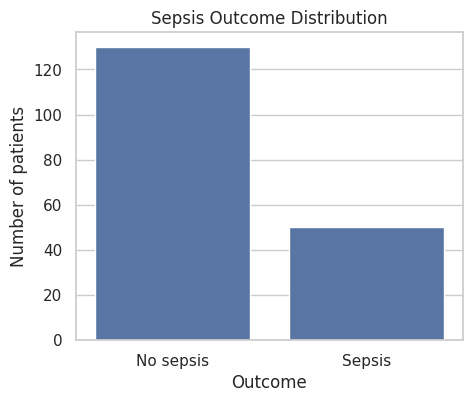

In [ ]:
plt.figure(figsize=(5, 4))
sns.countplot(data=icu, x="developed_sepsis")
plt.xticks([0, 1], ["No sepsis", "Sepsis"])
plt.title("Sepsis Outcome Distribution")
plt.xlabel("Outcome")
plt.ylabel("Number of patients")
plt.show()

In [ ]:
#the benchmark
print("Accuracy of always predicting 'no sepsis':", round((icu["developed_sepsis"] == 0).mean() * 100, 1), "%")

Accuracy of always predicting 'no sepsis': 72.2 %


### Target variable findings
- 50 of 180 patients (27.8%) developed sepsis; 130 (72.2%) did not.
- The outcome is imbalanced. A model that always predicted "no sepsis" would be 72.2% accurate while missing every case, so accuracy alone will not be used to judge the models; recall, precision, F1, ROC-AUC and the confusion matrix will be reported.
- A stratified train/test split will be used so both sets keep this class mix (Decision Log I06).

## 6. EDA: Sepsis by Age, Gender and ICU Length of Stay
**Question:** How do sepsis rates differ by age group and gender, and how do age and ICU length of stay compare between patients with and without sepsis?
**Note:** age groups were set before viewing results: 18-40, 41-60, 61-75 and 76+.

In [ ]:
#create age groups

icu["age_group"] = pd.cut(icu["age"], bins=[0, 40, 60, 75, 120], labels=["18-40", "41-60", "61-75", "76+"])
icu["age_group"].value_counts().sort_index()

,count
age_group,
18-40,27
41-60,77
61-75,49
76+,27


In [ ]:
#sepsis rate by age group, with counts

age_rates = icu.groupby("age_group", observed=True)["developed_sepsis"].agg(["count", "sum", "mean"])
age_rates.columns = ["patients", "sepsis_cases", "sepsis_rate"]
age_rates["sepsis_rate"] = (age_rates["sepsis_rate"] * 100).round(1)
age_rates

,patients,sepsis_cases,sepsis_rate
age_group,,,
18-40,27,6,22.2
41-60,77,22,28.6
61-75,49,15,30.6
76+,27,7,25.9


In [ ]:
#sepsis rate by gender
gender_rates = icu.groupby("gender")["developed_sepsis"].agg(["count", "sum", "mean"])
gender_rates.columns = ["patients", "sepsis_cases", "sepsis_rate"]
gender_rates["sepsis_rate"] = (gender_rates["sepsis_rate"] * 100).round(1)
gender_rates

,patients,sepsis_cases,sepsis_rate
gender,,,
Female,93,24,25.8
Male,87,26,29.9


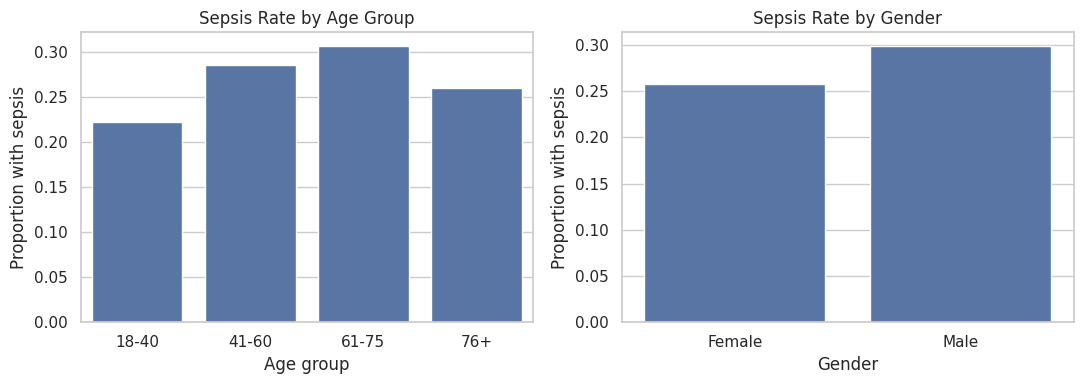

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=icu, x="age_group", y="developed_sepsis", errorbar=None, ax=axes[0])
axes[0].set_title("Sepsis Rate by Age Group")
axes[0].set_xlabel("Age group")
axes[0].set_ylabel("Proportion with sepsis")
sns.barplot(data=icu, x="gender", y="developed_sepsis", errorbar=None, ax=axes[1])
axes[1].set_title("Sepsis Rate by Gender")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Proportion with sepsis")
plt.tight_layout()
plt.show()

In [ ]:
#age and ICU stay by outcome
icu.groupby("developed_sepsis")[["age", "los_hours"]].agg(["count", "mean", "median"]).round(1)

age              los_hours             
                 count  mean median     count  mean median
developed_sepsis                                          
0                  130  57.3   58.0       130  39.0   36.5
1                   50  57.2   58.5        50  43.3   47.0

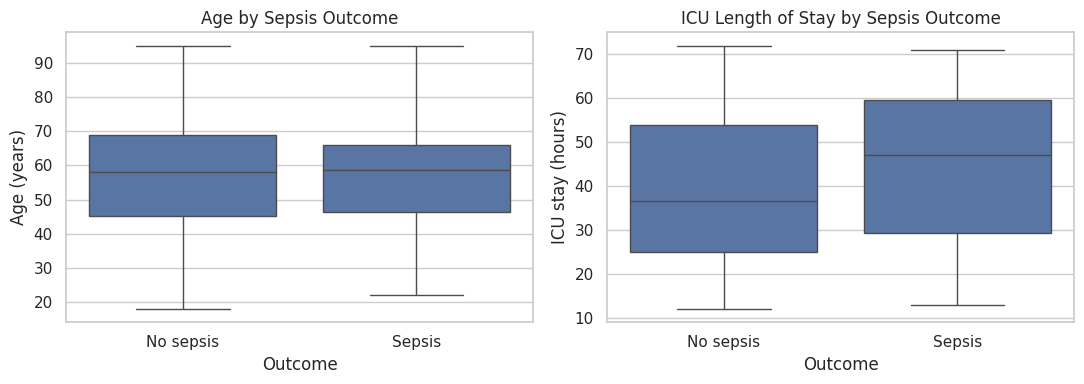

In [ ]:
#charts of age and ICU stay by outcome

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=icu, x="developed_sepsis", y="age", ax=axes[0])
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["No sepsis", "Sepsis"])
axes[0].set_title("Age by Sepsis Outcome")
axes[0].set_xlabel("Outcome"); axes[0].set_ylabel("Age (years)")
sns.boxplot(data=icu, x="developed_sepsis", y="los_hours", ax=axes[1])
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["No sepsis", "Sepsis"])
axes[1].set_title("ICU Length of Stay by Sepsis Outcome")
axes[1].set_xlabel("Outcome"); axes[1].set_ylabel("ICU stay (hours)")
plt.tight_layout()
plt.show()

In [ ]:
#is the difference bigger than chance?

from scipy import stats

print("Gender vs sepsis, p-value:", round(stats.chi2_contingency(pd.crosstab(icu["gender"], icu["developed_sepsis"]))[1], 3))
print("Age group vs sepsis, p-value:", round(stats.chi2_contingency(pd.crosstab(icu["age_group"], icu["developed_sepsis"]))[1], 3))

sep = icu[icu["developed_sepsis"] == 1]
nosep = icu[icu["developed_sepsis"] == 0]
print("Age, sepsis vs no sepsis, p-value:", round(stats.mannwhitneyu(sep["age"], nosep["age"])[1], 3))
print("ICU stay, sepsis vs no sepsis, p-value:", round(stats.mannwhitneyu(sep["los_hours"], nosep["los_hours"])[1], 3))

Gender vs sepsis, p-value: 0.657
Age group vs sepsis, p-value: 0.877
Age, sepsis vs no sepsis, p-value: 1.0
ICU stay, sepsis vs no sepsis, p-value: 0.134


### Findings: sepsis by patient group
- Sepsis rates were 25.8% for women (24 of 93) and 29.9% for men (26 of 87), and ranged from 22.2% to 30.6% across age groups (6 to 22 cases per group); these differences are small and not statistically distinguishable from chance (p = 0.66 and 0.88).
- Age was virtually identical between patients with and without sepsis (mean 57.2 vs 57.3 years).
- ICU stay was longer for patients who developed sepsis (mean 43.3 vs 39.0 hours; median 47.0 vs 36.5), but the difference was not statistically clear (p = 0.13). Sepsis may itself lengthen a stay, so length of stay is an association, not an early predictor.
- With 50 sepsis cases split across groups, these comparisons are small-sample and should be treated as exploratory; they do not identify a patient group to target.

## 7. EDA: Sepsis Onset Timing
**Question:** Among patients who developed sepsis, how many hours into the ICU stay did it appear?
**Caution:** sepsis_onset_hour exists only because the outcome occurred, so it is analysed descriptively here and is never used as a model feature (Decision Log I01).

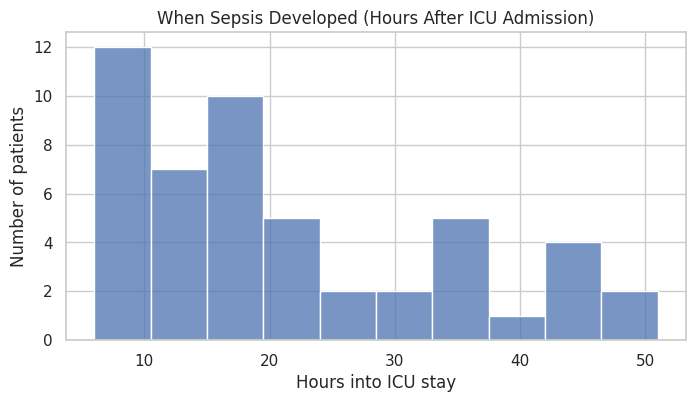

In [ ]:
#histogram of onset hours

onset = icu.loc[icu["developed_sepsis"] == 1, "sepsis_onset_hour"]

plt.figure(figsize=(8, 4))
sns.histplot(onset, bins=10)
plt.title("When Sepsis Developed (Hours After ICU Admission)")
plt.xlabel("Hours into ICU stay")
plt.ylabel("Number of patients")
plt.show()

In [ ]:
#how quickly after admission?

for hours in [12, 24, 36, 48]:
    count = (onset <= hours).sum()
    print("Sepsis within", hours, "hours:", count, "of", len(onset), "patients (", round(count / len(onset) * 100), "% )")

Sepsis within 12 hours: 17 of 50 patients ( 34 % )
Sepsis within 24 hours: 34 of 50 patients ( 68 % )
Sepsis within 36 hours: 43 of 50 patients ( 86 % )
Sepsis within 48 hours: 48 of 50 patients ( 96 % )


### Findings: sepsis onset timing
- Among the 50 patients who developed sepsis, onset occurred between 6 and 51 hours after ICU admission (median 17.5 hours).
- About a third (34%) developed sepsis within 12 hours, two thirds (68%) within 24 hours, and 96% within 48 hours.
- The pattern suggests the first one to two days of an ICU stay are the period of highest risk to monitor, subject to the small sample (50 cases) and synthetic data.
- Onset time is only known for patients who developed sepsis, so it describes timing and is not used for prediction.

## 8. Modelling Preparation
**Target:** developed_sepsis (classification).
**Prediction assumption:** vital signs, laboratory values and demographics are assumed to be recorded before sepsis onset (see Decision Log I05).
**Features used (13):** age, gender, heart_rate_bpm, systolic_bp_mmhg, respiratory_rate_bpm, temperature_c, spo2_percent, wbc_10e9_l, lactate_mmol_l, creatinine_mg_dl, platelets_10e9_l, gcs_score, urine_output_ml_kg_hr.
**Excluded:** patient_id (identifier); sepsis_onset_hour (exists only because of the outcome); los_hours (known only at discharge); antibiotics, vasopressors and mechanical ventilation (timing not documented); age_group (duplicates age).
**Order of steps:** choose features, stratified split, fill gaps using training data only, then scale.

In [ ]:
#determing the features and target

features = ["age", "gender", "heart_rate_bpm", "systolic_bp_mmhg", "respiratory_rate_bpm",
            "temperature_c", "spo2_percent", "wbc_10e9_l", "lactate_mmol_l", "creatinine_mg_dl",
            "platelets_10e9_l", "gcs_score", "urine_output_ml_kg_hr"]

X = pd.get_dummies(icu[features], columns=["gender"], drop_first=True, dtype=int)
y = icu["developed_sepsis"]
print(X.shape)
X.head()

(180, 13)


,age,heart_rate_bpm,systolic_bp_mmhg,respiratory_rate_bpm,temperature_c,spo2_percent,wbc_10e9_l,lactate_mmol_l,creatinine_mg_dl,platelets_10e9_l,gcs_score,urine_output_ml_kg_hr,gender_Male
0,58,85.7,98.3,22.5,37.06,94.8,10.17,1.75,1.29,179.5,14,1.30,0
1,41,77.7,129.0,22.6,37.15,96.2,7.80,1.34,0.62,258.5,13,1.17,0
2,57,73.2,129.6,12.2,36.66,98.8,4.90,1.00,1.33,251.8,13,NaN,1
3,79,80.1,119.0,12.2,36.42,96.7,9.31,1.37,0.73,257.1,15,0.54,0
4,60,80.0,118.8,18.4,36.60,98.5,7.70,1.46,1.47,218.3,15,1.43,1


In [ ]:
#stratified split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Sepsis in train:", y_train.sum(), " Sepsis in test:", y_test.sum())

Train: (144, 13)  Test: (36, 13)
Sepsis in train: 40  Sepsis in test: 10


In [ ]:
#fill the gaps using the training set only

imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=X.columns, index=X_test.index)
print("Missing values left:", X_train_imp.isnull().sum().sum(), X_test_imp.isnull().sum().sum())

Missing values left: 0 0


In [ ]:
#put the numbers on the same scale
scaler = StandardScaler()
X_train_sc = pd.DataFrame(scaler.fit_transform(X_train_imp), columns=X.columns, index=X_train.index)
X_test_sc = pd.DataFrame(scaler.transform(X_test_imp), columns=X.columns, index=X_test.index)
X_train_sc.describe().T[["mean", "std"]].round(2).head()

,mean,std
age,0.0,1.0
heart_rate_bpm,-0.0,1.0
systolic_bp_mmhg,0.0,1.0
respiratory_rate_bpm,-0.0,1.0
temperature_c,-0.0,1.0


### Modelling preparation summary
- 13 features selected; 180 patients split 80/20 with stratification: 144 train (40 sepsis) and 36 test (10 sepsis).
- Missing values (30 in total) were filled with training-set medians after the split; the target was never imputed.
- Features were standardised using the training set only.
- The test set contains only 10 sepsis cases, so test results will be unstable and should be read cautiously.

### Note on missing values
- Missing vital and laboratory values (30 in total, under 5% of any column) were filled with training-set medians, a simple baseline suited to small gaps.
- In real hospital data, a missing value can be informative (for example, a test not ordered because the patient appeared stable), and the reason for the missingness cannot be established from this synthetic dataset.
- More advanced approaches such as multiple imputation, or adding a "not measured" indicator, were outside the scope of this baseline analysis (see Limitations).

## 9. Modelling: Predicting Sepsis
**Models:** Logistic Regression, Decision Tree and Random Forest, trained on the training set and evaluated on the held-out test set.
**Settings:** simple baseline settings, no parameter search (random_state=42 for repeatability; Decision Tree limited to depth 3 so it stays readable and does not memorise 144 patients).
**Evaluation:** accuracy, precision, recall, F1, ROC-AUC and a confusion matrix for each model. Accuracy alone is not used, because 72.2% of patients did not develop sepsis.

In [ ]:
#: one helper that trains, tests and scores every model the same way
roc_data = {}

def evaluate_classifier(name, model):
    model.fit(X_train_sc, y_train)                    # 1. learn from the training patients
    pred = model.predict(X_test_sc)                   # 2. predict yes/no for the test patients
    prob = model.predict_proba(X_test_sc)[:, 1]       # 3. predicted chance of sepsis
    roc_data[name] = prob                             # keep for the ROC chart later
    cm = confusion_matrix(y_test, pred)               # 4. count right and wrong predictions
    plt.figure(figsize=(4, 3.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["No sepsis", "Sepsis"], yticklabels=["No sepsis", "Sepsis"])
    plt.title(name + ": Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    return {"Model": name,                            # 5. score it
            "Accuracy": round(accuracy_score(y_test, pred), 3),
            "Precision": round(precision_score(y_test, pred, zero_division=0), 3),
            "Recall": round(recall_score(y_test, pred), 3),
            "F1": round(f1_score(y_test, pred), 3),
            "ROC-AUC": round(roc_auc_score(y_test, prob), 3)}

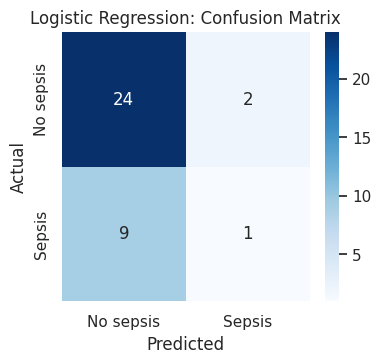

In [ ]:
#Logistic Regression
results = []
results.append(evaluate_classifier("Logistic Regression", LogisticRegression(random_state=42, max_iter=1000)))

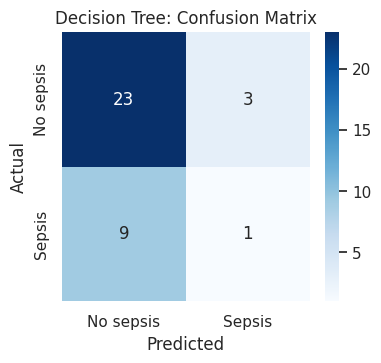

In [ ]:
#decision tree
results.append(evaluate_classifier("Decision Tree", DecisionTreeClassifier(max_depth=3, random_state=42)))

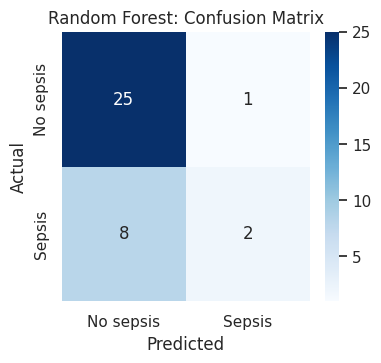

In [ ]:
#random forest
results.append(evaluate_classifier("Random Forest", RandomForestClassifier(n_estimators=100, random_state=42)))

In [ ]:
#The comparison table
pd.DataFrame(results)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.694,0.333,0.1,0.154,0.658
1,Decision Tree,0.667,0.250,0.1,0.143,0.579
2,Random Forest,0.750,0.667,0.2,0.308,0.713


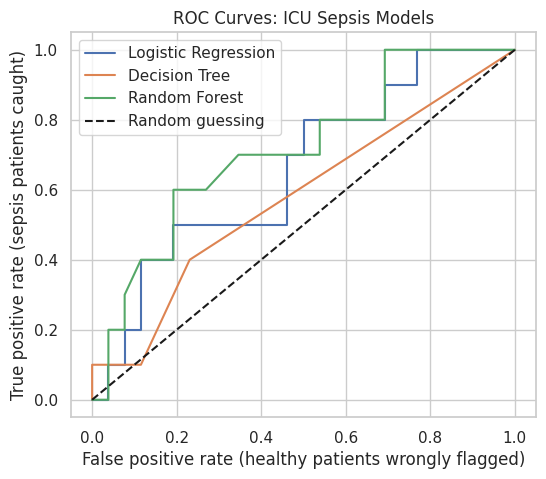

In [ ]:
#ROC chart (the brief’s model-performance visual)
from sklearn.metrics import roc_curve

plt.figure(figsize=(6, 5))
for name, prob in roc_data.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False positive rate (healthy patients wrongly flagged)")
plt.ylabel("True positive rate (sepsis patients caught)")
plt.title("ROC Curves: ICU Sepsis Models")
plt.legend()
plt.show()

## 10. Error Analysis: What the Confusion Matrices Mean in the ICU
Each matrix counts the 36 test patients (26 without sepsis, 10 with sepsis) in four groups:
- True negative (top left): no sepsis, correctly cleared.
- False positive (top right): no sepsis, wrongly flagged. A false alarm.
- False negative (bottom left): sepsis, missed. A septic patient the model called safe.
- True positive (bottom right): sepsis, correctly caught.

### Model findings (ICU)
- Accuracy ranged from 66.7% to 75.0%. Always predicting "no sepsis" would score 72.2%, so only the Random Forest (75.0%) beat that benchmark, by one patient. Accuracy is therefore not a useful measure here.
- Recall was low for every model: Logistic Regression and the Decision Tree caught 1 of 10 sepsis patients and the Random Forest caught 2 of 10. Eight to nine of every ten septic patients in the test set were missed.
- ROC-AUC (0.58 to 0.71) shows modest discrimination at best; the Random Forest was highest (0.71) and the Decision Tree lowest (0.58). 0.5 would be random guessing.
- The test set has only 10 sepsis cases, so a single patient changes recall by ten percentage points; differences between models are not reliable and no model should be declared clearly better.
- Weak performance is consistent with the audit and EDA: the clinical variables show little separation between outcome groups (for example, mean platelets 215 vs 238, mean respiratory rate 18.8 vs 17.4).
- These models are not suitable for clinical use; they are baseline demonstrations on a small, synthetic dataset.

### Consequences of errors
- **False negative (missed sepsis):** a septic patient is classed as low risk, so treatment such as antibiotics may be delayed. Sepsis can worsen within hours, and delay is associated with higher mortality and longer ICU stays. This is the more serious error.
- **False positive (false alarm):** a patient without sepsis is flagged, causing extra tests, possible unnecessary antibiotics, staff workload and, if frequent, alert fatigue, where staff begin to ignore warnings.
- In sepsis screening, missing a case usually costs more than a false alarm, so recall (the share of true sepsis cases caught) is prioritised over precision. By that standard, all three models perform poorly.

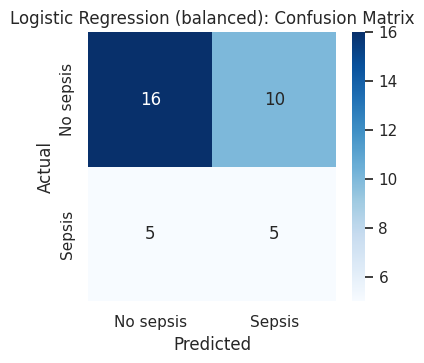

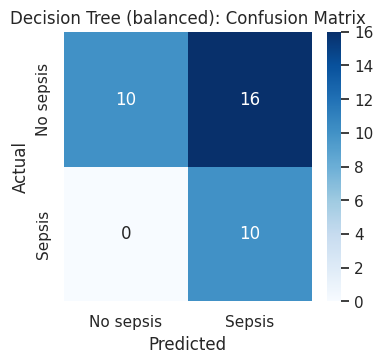

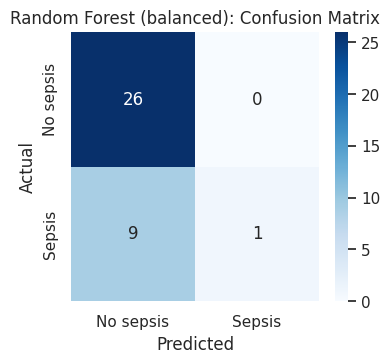

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression (balanced),0.583,0.333,0.5,0.400,0.688
1,Decision Tree (balanced),0.556,0.385,1.0,0.556,0.669
2,Random Forest (balanced),0.750,1.000,0.1,0.182,0.719


In [ ]:
#comparism

results_balanced = []
for name, model in [
    ("Logistic Regression (balanced)", LogisticRegression(random_state=42, max_iter=1000, class_weight="balanced")),
    ("Decision Tree (balanced)", DecisionTreeClassifier(max_depth=3, random_state=42, class_weight="balanced")),
    ("Random Forest (balanced)", RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced"))]:
    results_balanced.append(evaluate_classifier(name, model))
pd.DataFrame(results_balanced)

## Business Implications (ICU)
- Sepsis developed early: about two thirds of cases (68%) appeared within 24 hours and 96% within 48 hours, so monitoring effort is best concentrated on the first one to two days of an ICU stay.
- No age or gender group stood out as higher risk (differences were within chance), so risk screening should not rely on demographics alone.
- The baseline models identified few sepsis cases (recall 10% to 20%) and are not suitable for clinical use; the measured variables carried little predictive signal in this dataset.
- Missed sepsis is the costlier error. Re-running the models with class weighting raised recall (up to 50% to 100% for two models) but produced many more false alarms, so any real screening tool would need thresholds agreed with clinicians.
- Better prediction would need larger samples and time-stamped, repeated measurements, which would also allow the assumption that measurements precede onset to be tested.

### Limitations (ICU)
- 180 patients with only 50 sepsis cases; the test set holds 10, so results are unstable.
- The clinical variables are synthetic and weakly related to the outcome; results should not be generalised to real patients.
- No timestamps on vitals and labs; the assumption that they precede onset cannot be verified.
- Missing values were filled with a simple median baseline; missingness may be informative in real data.
- One train/test split and no cross-validation; no parameter search, by design.
- Treatments and length of stay were excluded because their timing relative to sepsis is unknown.
- Associations only; no causal claims.

## 11. Save the Cleaned Data
The merged working table (icu), including the age_group column, is saved as a separate processed file. The raw files are unchanged.

In [ ]:
icu.to_csv("ICU_Sepsis_Merged_Cleaned.csv", index=False)